In [46]:
# Import packages
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, classification_report


In [47]:
# Import packages and configure paths

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data/clean/trips_clean.parquet').exists())
OUT = ROOT / 'results/rider_type'
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
HIGH_SCORE = 0.8
MIN_GROUP = 20
SPLITS = {
    'train': ('2025-04-01', '2025-08-01', 150_000),
    'valid': ('2025-08-01', '2025-09-01', 50_000),
    'test': ('2025-09-01', '2025-10-01', 50_000),
}


In [48]:
# Load reproducible ride samples with chronological splits
con = duckdb.connect()
con.execute('SET threads=4')
con.execute("SET memory_limit='3GB'")
con.read_parquet(str(ROOT / 'data/clean/trips_clean.parquet')).create_view('trips')
frames = {}
for name, (start, end, size) in SPLITS.items():
    frames[name] = con.sql(f"""
        SELECT ride_id, started_at, member_casual, rideable_type,
               start_station_id, end_station_id, start_station_name,
               start_lat, start_lng, end_lat, end_lng, duration_seconds
        FROM trips
        WHERE started_at >= TIMESTAMP '{start}' AND started_at < TIMESTAMP '{end}'
          AND member_casual IN ('member', 'casual') AND duration_eligible
        ORDER BY hash(ride_id, {SEED}), ride_id
        LIMIT {size}
    """).df()
con.close()
for name, df in frames.items():
    assert not df.empty and df.member_casual.nunique() == 2 and df.ride_id.is_unique
    print(name, len(df), 'member share:', round(df.member_casual.eq('member').mean(), 4))
assert frames['train'].started_at.max() < frames['valid'].started_at.min()
assert frames['valid'].started_at.max() < frames['test'].started_at.min()


train 150000 member share: 0.8068
valid 50000 member share: 0.777
test 50000 member share: 0.8117


In [49]:
# Create timing, bicycle, station, duration, and endpoint-distance features
for df in frames.values():
    df['hour'] = df.started_at.dt.hour
    df['weekday'] = df.started_at.dt.dayofweek
    df['hour_sin'] = np.sin(2 * np.pi * df.hour / 24)
    df['hour_cos'] = np.cos(2 * np.pi * df.hour / 24)
    df['weekday_sin'] = np.sin(2 * np.pi * df.weekday / 7)
    df['weekday_cos'] = np.cos(2 * np.pi * df.weekday / 7)
    df['weekend'] = (df.weekday >= 5).astype(int)
    df['log_duration'] = np.log1p(df.duration_seconds / 60)
    lat1, lon1, lat2, lon2 = [np.deg2rad(df[c].to_numpy(dtype=float)) for c in
                             ['start_lat', 'start_lng', 'end_lat', 'end_lng']]
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    df['distance_km'] = 6371.0088 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    df['log_distance'] = np.log1p(df.distance_km)
    df['target'] = df.member_casual.eq('member').astype(int)
    for c in ['rideable_type', 'start_station_id', 'end_station_id']:
        df[c] = df[c].fillna('__missing__').astype(str)
train, valid, test = [frames[k] for k in ['train', 'valid', 'test']]
categorical = ['rideable_type', 'start_station_id', 'end_station_id']
numerical = ['hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos', 'weekend',
             'log_duration', 'log_distance', 'start_lat', 'start_lng', 'end_lat', 'end_lng']
features = categorical + numerical


In [50]:
# Build logistic regression, random forest, and gradient boosting pipelines
preprocess = ColumnTransformer([
    ('categories', OneHotEncoder(handle_unknown='infrequent_if_exist',
                                 min_frequency=50, max_categories=200), categorical),
    ('numbers', Pipeline([
        ('impute', SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)),
        ('scale', StandardScaler()),
    ]), numerical),
], sparse_threshold=1.0)
models = {
    'Logistic regression': Pipeline([
        ('preprocess', clone(preprocess)),
        ('model', LogisticRegression(C=0.1, max_iter=2000, random_state=SEED)),
    ]),
    'Random forest': Pipeline([
        ('preprocess', clone(preprocess)),
        ('model', RandomForestClassifier(n_estimators=120, max_depth=20,
                                        min_samples_leaf=20, n_jobs=4, random_state=SEED)),
    ]),
    'Gradient boosting': Pipeline([
        ('preprocess', clone(preprocess)),
        ('model', GradientBoostingClassifier(
            n_estimators=150, learning_rate=0.1, max_depth=3,
            min_samples_leaf=20, random_state=SEED)),
    ]),
}
def metrics(y, p):
    pred = (p >= 0.5).astype(int)
    return {'precision_member': precision_score(y, pred, zero_division=0),
            'recall_member': recall_score(y, pred, zero_division=0),
            'f1_member': f1_score(y, pred, zero_division=0),
            'roc_auc': roc_auc_score(y, p)}


In [51]:
# Compare models on August validation and select by ROC-AUC
validation_rows = []
for name, model in models.items():
    model.fit(train[features], train.target)
    p = model.predict_proba(valid[features])[:, 1]
    validation_rows.append({'model': name, **metrics(valid.target, p)})
validation_results = pd.DataFrame(validation_rows)
selected_name = validation_results.loc[validation_results.roc_auc.idxmax(), 'model']
display(validation_results)
print('Validation-selected model:', selected_name)
validation_results.to_csv(OUT / 'validation_metrics.csv', index=False)


,model,precision_member,recall_member,f1_member,roc_auc
0,Logistic regression,0.796116,0.976990,0.877327,0.715833
1,Random forest,0.777996,0.999768,0.875049,0.710679
2,Gradient boosting,0.800797,0.977170,0.880236,0.735482


Validation-selected model: Gradient boosting


In [52]:
# Refit on April–August and evaluate all three models on September
combined = pd.concat([train, valid], ignore_index=True)
probabilities, test_rows = {}, []
for name, model in models.items():
    model.fit(combined[features], combined.target)
    p = model.predict_proba(test[features])[:, 1]
    probabilities[name] = p
    test_rows.append({'model': name, **metrics(test.target, p)})
    print(name)
    print(classification_report(test.target, p >= 0.5,
                                target_names=['casual', 'member'], zero_division=0))
test_results = pd.DataFrame(test_rows)
display(test_results)
test_results.to_csv(OUT / 'test_metrics.csv', index=False)


Logistic regression
              precision    recall  f1-score   support

      casual       0.56      0.10      0.17      9415
      member       0.82      0.98      0.90     40585

    accuracy                           0.82     50000
   macro avg       0.69      0.54      0.53     50000
weighted avg       0.77      0.82      0.76     50000

Random forest
              precision    recall  f1-score   support

      casual       0.95      0.01      0.01      9415
      member       0.81      1.00      0.90     40585

    accuracy                           0.81     50000
   macro avg       0.88      0.50      0.46     50000
weighted avg       0.84      0.81      0.73     50000

Gradient boosting
              precision    recall  f1-score   support

      casual       0.60      0.12      0.19      9415
      member       0.83      0.98      0.90     40585

    accuracy                           0.82     50000
   macro avg       0.71      0.55      0.55     50000
weighted avg       0.7

,model,precision_member,recall_member,f1_member,roc_auc
0,Logistic regression,0.824594,0.981915,0.896404,0.692991
1,Random forest,0.812807,0.999901,0.896699,0.682914
2,Gradient boosting,0.827210,0.982013,0.897989,0.708461


In [53]:
# Summarize when and where casual rides have high member-similarity scores
casual = test.loc[test.target.eq(0)].copy()
casual['member_score'] = probabilities[selected_name][test.target.eq(0).to_numpy()]
casual['high_score'] = casual.member_score >= HIGH_SCORE
print('Casual rides:', len(casual))
print('High-score rides:', int(casual.high_score.sum()))
print('High-score share:', round(casual.high_score.mean(), 4))
def group_summary(keys):
    table = casual.groupby(keys, dropna=False).agg(
        casual_rides=('ride_id', 'size'), high_score_rides=('high_score', 'sum'),
        mean_member_score=('member_score', 'mean')).reset_index()
    table['high_score_share'] = table.high_score_rides / table.casual_rides
    return table
hour_summary = group_summary(['hour'])
time_summary = group_summary(['weekday', 'hour'])
station_summary = group_summary(['start_station_id'])
station_names = (casual.sort_values(['started_at', 'ride_id'])
                 .drop_duplicates('start_station_id', keep='last')
                 [['start_station_id', 'start_station_name']])
station_summary = station_summary.merge(station_names, on='start_station_id', validate='one_to_one')
ranked_stations = station_summary.loc[
    (station_summary.casual_rides >= MIN_GROUP)
    & station_summary.start_station_id.ne('__missing__')
].sort_values('high_score_share', ascending=False)
display(ranked_stations.head(15))
for name, table in [('casual_by_hour', hour_summary), ('casual_by_weekday_hour', time_summary),
                    ('casual_by_start_station', station_summary)]:
    table.to_csv(OUT / f'{name}.csv', index=False)
casual.to_csv(OUT / 'casual_ride_scores.csv', index=False)


Casual rides: 9415
High-score rides: 3696
High-score share: 0.3926


,start_station_id,casual_rides,high_score_rides,mean_member_score,high_score_share,start_station_name
1246,7059.08,20,13,0.799487,0.650000,West End Ave & W 60 St
822,5905.12,22,14,0.776221,0.636364,Broadway & E 14 St
630,5308.04,28,17,0.793531,0.607143,Metropolitan Ave & Bedford Ave
1018,6450.05,24,14,0.743518,0.583333,8 Ave & W 31 St
306,4395.07,25,14,0.765260,0.560000,Hanson Pl & Ashland Pl
946,6257.03,22,12,0.760694,0.545455,W 24 St & 7 Ave
1150,6756.01,24,13,0.764497,0.541667,W 43 St & 10 Ave
739,5593.01,24,13,0.765171,0.541667,E 1 St & 1 Ave
921,6197.08,24,13,0.789135,0.541667,E 33 St & 1 Ave
686,5445.02,22,11,0.798720,0.500000,Suffolk St & Stanton St


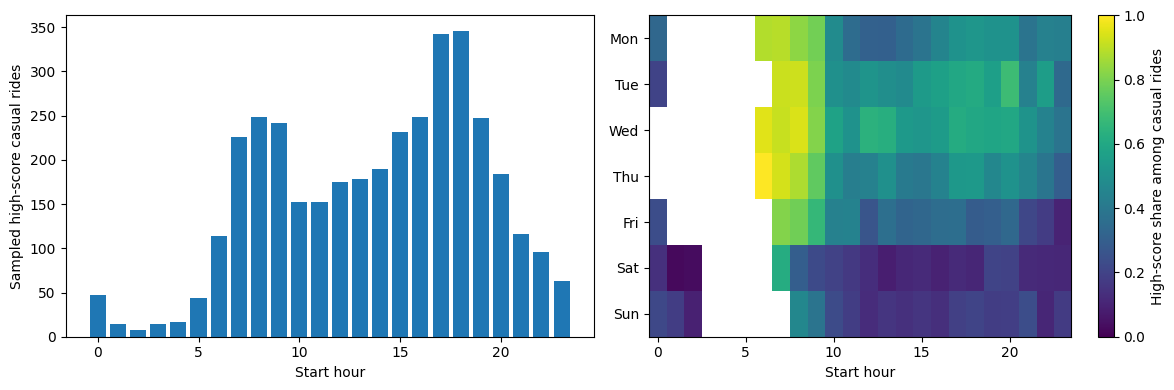

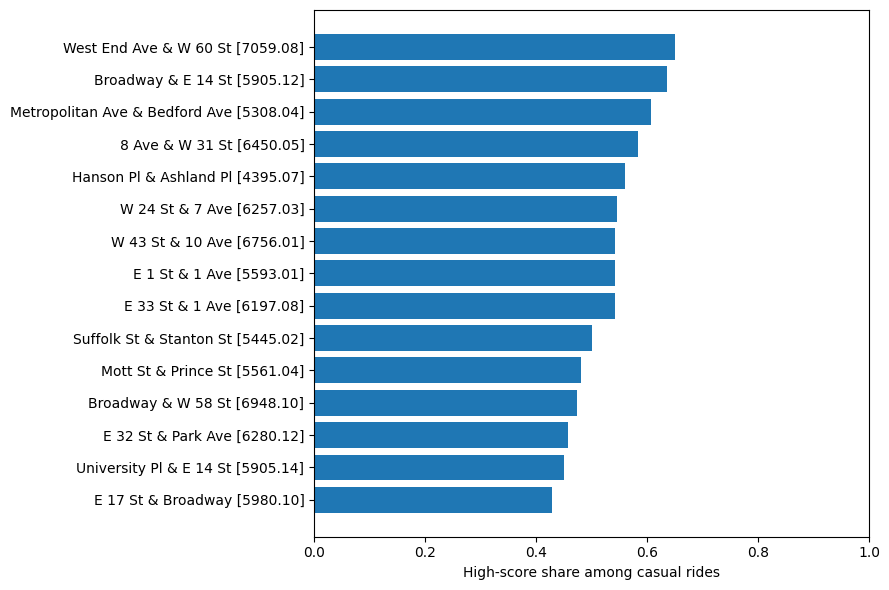

In [54]:
# Plot held-out member-like casual ride patterns, not membership purchase probability
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(hour_summary.hour, hour_summary.high_score_rides)
axes[0].set(xlabel='Start hour', ylabel='Sampled high-score casual rides')
heat = (time_summary.loc[time_summary.casual_rides >= MIN_GROUP]
        .pivot(index='weekday', columns='hour', values='high_score_share')
        .reindex(index=range(7), columns=range(24)))
im = axes[1].imshow(heat, aspect='auto', vmin=0, vmax=1)
axes[1].set_yticks(range(7), ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
axes[1].set_xlabel('Start hour')
fig.colorbar(im, ax=axes[1], label='High-score share among casual rides')
fig.tight_layout()
fig.savefig(OUT / 'casual_time_patterns.png', dpi=180)
plt.show()
if not ranked_stations.empty:
    top = ranked_stations.head(15).iloc[::-1]
    labels = top.start_station_name.fillna(top.start_station_id) + ' [' + top.start_station_id + ']'
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(labels, top.high_score_share)
    ax.set(xlim=(0, 1), xlabel='High-score share among casual rides')
    fig.tight_layout()
    fig.savefig(OUT / 'casual_station_patterns.png', dpi=180, bbox_inches='tight')
    plt.show()


Gradient boosting was selected using August validation ROC-AUC (0.735). On the September test set, its ROC-AUC was 0.708, exceeding the logistic regression baseline (0.693) and random forest (0.683). Its member precision, recall, and F1 were 0.827, 0.982, and 0.898. However, it identified only about 12% of casual rides at the 0.5 threshold, indicating a strong tendency to predict the majority member class. Among 9,415 casual test rides, 3,696 (39.26%) received a member score of at least 0.8. These scores indicate member-like ride patterns, not membership purchase probability; station comparisons remain exploratory because group samples are small.
